# GANisme — 04. Appliquer le cours : jeu homogène, pipeline, 64×64 puis 128×128

Ce notebook applique le how-to **« Traitement d'images : fondamentaux + spécificités GAN »** (La Plateforme)
et teste ses règles d'or sur nos données :

| Règle du cours | Ce que nous faisons |
| --- | --- |
| 1. Commencer petit (64×64), passer à 128 ensuite | DCGAN 64×64, puis 128×128 |
| 2. Normaliser en [−1, 1] | `Normalize(mean=0.5, std=0.5)` après `ToTensor` |
| 3. Augmenter prudemment | miroir horizontal seulement |
| 4. Dataset homogène | **un seul genre : les portraits** |
| Redimensionner dès le téléchargement, dossier dédié | `data/processed/portraits_128/` (train / eval) |
| Visualiser 16 images après le pipeline | section 3 |

**Pourquoi ?** Notre modèle « tous genres » (notebook 03) mélangeait 10 genres et 7 siècles : ses images
restaient abstraites. La règle 4 du cours prédit exactement ce résultat ; nous la testons en ne changeant
**que** le jeu de données.

## 0. Configuration

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
from IPython.display import Image as Show, display
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.utils import make_grid

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ganisme").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

IMAGES = ROOT / "data" / "processed" / "portraits_128"   # dossier dedie, deja en 128x128
print("Entrainement :", len(list((IMAGES / "train").glob("*.jpg"))), "| evaluation :",
      len(list((IMAGES / "eval").glob("*.jpg"))))

Entrainement : 3347 | evaluation : 390


## 1. Le jeu homogène : les portraits

Sélection avec les mêmes règles que le jeu principal (pas de vues de détail, pas de fresques, formats
raisonnables, une image par œuvre, découpage entraînement / évaluation **par œuvre**), restreinte au genre
`portrait`, avec au plus 60 tableaux par artiste : **4 068 portraits**, le maximum disponible dans le
catalogue. 3 737 ont pu être téléchargés (serveur lent : 325 échecs). C'est un peu sous la cible du cours
(5 000), mais le catalogue ne contient pas plus de portraits utilisables.

Les images sont archivées en 256×256 au téléchargement, puis enregistrées en **128×128 dans un dossier
dédié**, séparé en `train/` et `eval/` (`ganisme.pipeline.export_folder`).

## 2. Le pipeline du cours (slides 10 et 11)

L'ordre importe : `Resize → CenterCrop → RandomHorizontalFlip → ToTensor → Normalize`, jamais `Normalize`
avant `ToTensor`. Le `Dataset` lit les images à la demande et passe les fichiers illisibles.

In [2]:
IMAGE_SIZE = 128

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),                          # petit cote -> 128 (pas de deformation)
    transforms.CenterCrop(IMAGE_SIZE),                      # carre 128x128
    transforms.RandomHorizontalFlip(p=0.5),                 # augmentation sans danger
    transforms.ToTensor(),                                  # [0, 1], (3, H, W)
    transforms.Normalize(mean=[0.5] * 3, std=[0.5] * 3),    # -> [-1, 1], aligne sur le tanh de G
])


class PortraitDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.paths = sorted(Path(img_dir).glob("*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert("RGB")  # toujours 3 canaux
        except Exception:
            return self.__getitem__((idx + 1) % len(self))    # image illisible : on passe a la suivante
        return self.transform(img) if self.transform else img


dataset = PortraitDataset(IMAGES / "train", transform=transform)
print(len(dataset), "images d'entrainement")

3347 images d'entrainement


**`num_workers`** : le cours conseille 4 ou 8 pour ne pas laisser un GPU inactif. Dans un notebook sous
Windows, une classe définie dans le notebook ne peut pas être envoyée aux processus auxiliaires : on met
`num_workers=0` ici. Pour l'entraînement, la même classe est définie dans un module
(`src/ganisme/pipeline.py`), ce qui permet `num_workers=4`.

## 3. Vérification : 16 images à la sortie du DataLoader

*« Si c'est moche là, ce sera moche pour le GAN. »* On vérifie la forme, la plage des valeurs, puis on
regarde les images (ramenées de [−1, 1] à [0, 1] pour l'affichage).

Contrôle de contenu : un premier tirage contenait un nu partiel (*La Blonde aux seins nus*, Manet), qui
fait partie du jeu d'entraînement mais que nous ne montrons pas en présentation ; le tirage ci-dessous
(graine 3) a été vérifié.

Forme : (16, 3, 128, 128) | min -1.0 | max 1.0


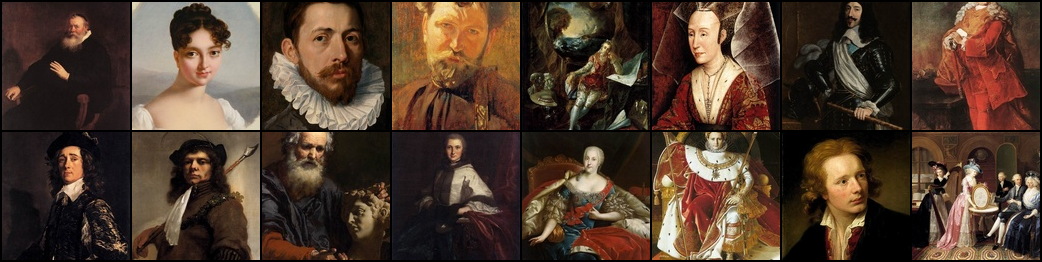

In [3]:
torch.manual_seed(3)
check = PortraitDataset(IMAGES / "train", transform=transform)
batch = next(iter(DataLoader(check, batch_size=16, shuffle=True, num_workers=0)))
print("Forme :", tuple(batch.shape), "| min", round(float(batch.min()), 3), "| max", round(float(batch.max()), 3))
assert batch.shape == (16, 3, IMAGE_SIZE, IMAGE_SIZE)
assert batch.min() >= -1 and batch.max() <= 1

grid = make_grid(batch, nrow=8, normalize=True, value_range=(-1, 1))
display(Image.fromarray((grid.permute(1, 2, 0).numpy() * 255).astype(np.uint8)))

Les images sont carrées, centrées sur le personnage, sans déformation, et les couleurs sont correctes
après dénormalisation : le pipeline est prêt pour le GAN.

**Limite** : le jeu n'est pas parfaitement homogène (portraits en pied, de groupe, équestres, quelques
dessins), mais beaucoup plus que le jeu « tous genres ».

## 4. Entraînement : 64×64 puis 128×128

Même DCGAN que le notebook 03 (code détaillé dans 03), avec une couche de plus dans chaque réseau en
128×128. Mêmes hyperparamètres (Adam, lr 0,0002, β1 = 0,5, lots de 128).

| | 64×64 | 128×128 |
| --- | --- | --- |
| Époques | 180 | 100 |
| Itérations | ≈ 4 700 (autant que le modèle tous genres) | ≈ 2 600 |
| Durée par époque (CPU, 16 threads) | ≈ 1 min | ≈ 5 min 20 |
| Paramètres du générateur | 3,6 M | 12,8 M |

Le 128×128 a été limité à 100 époques pour tenir dans une nuit de calcul : la comparaison 64 / 128 n'est
donc pas à entraînement égal. Les deux entraînements ont été lancés en ligne de commande
(`scripts/train_portraits.sh`, relance automatique en cas de plantage) ; la cellule ci-dessous reprend
depuis les checkpoints et ne recalcule rien.

In [4]:
from ganisme.dcgan import Config, Discriminator, Generator, train

results = {}
for size, epochs in ((64, 180), (128, 100)):
    cfg = Config(images=str(IMAGES), image_size=size, epochs=epochs, run_dir=str(ROOT / "runs" / f"portraits_{size}"))
    results[size] = train(cfg)
    G = Generator(cfg.z_dim, cfg.ngf, size)
    print(f"{size}x{size} : {results[size]['epochs_done']} epoques, {results[size]['iterations']} iterations, "
          f"G {sum(p.numel() for p in G.parameters()):,} parametres")
    assert results[size]["epochs_done"] == epochs

Reprise a l'epoque 180 (iteration 4680)


64x64 : 180 epoques, 4680 iterations, G 3,576,704 parametres


Reprise a l'epoque 100 (iteration 2600)


128x128 : 100 epoques, 2600 iterations, G 12,786,560 parametres


## 5. Évaluation et comparaison des modèles (Q8)

In [5]:
def load(path):
    return json.loads((ROOT / path).read_text())

models = {
    "Tous genres (v1, 64x64)": load("reports/training/metrics.json"),
    "Portraits 64x64": load("reports/portraits_64/metrics.json"),
    "Portraits 128x128": load("reports/portraits_128/metrics.json"),
}
print(f"{'':26}{'FID':>8}{'Reference':>11}{'Ecart':>8}{'KID':>8}{'Iterations':>12}")
for name, m in models.items():
    print(f"{name:26}{m['fid']:8.0f}{m['fid_real']:11.0f}{m['fid'] / m['fid_real']:7.1f}x{m['kid']:8.3f}{m['iterations']:12}")

                               FID  Reference   Ecart     KID  Iterations
Tous genres (v1, 64x64)        211         62    3.4x   0.150        4700
Portraits 64x64                204         73    2.8x   0.135        4680
Portraits 128x128              286         76    3.8x   0.225        2600


**Lecture prudente** : les trois modèles ne sont pas évalués sur les mêmes peintures (jeu tous genres
contre portraits) ni à la même résolution. On compare donc l'**écart** de chacun à sa propre référence
(FID entre deux ensembles de vraies peintures de même taille), et les images.

Portraits 64x64 : images generees, puis generee / plus proche reelle


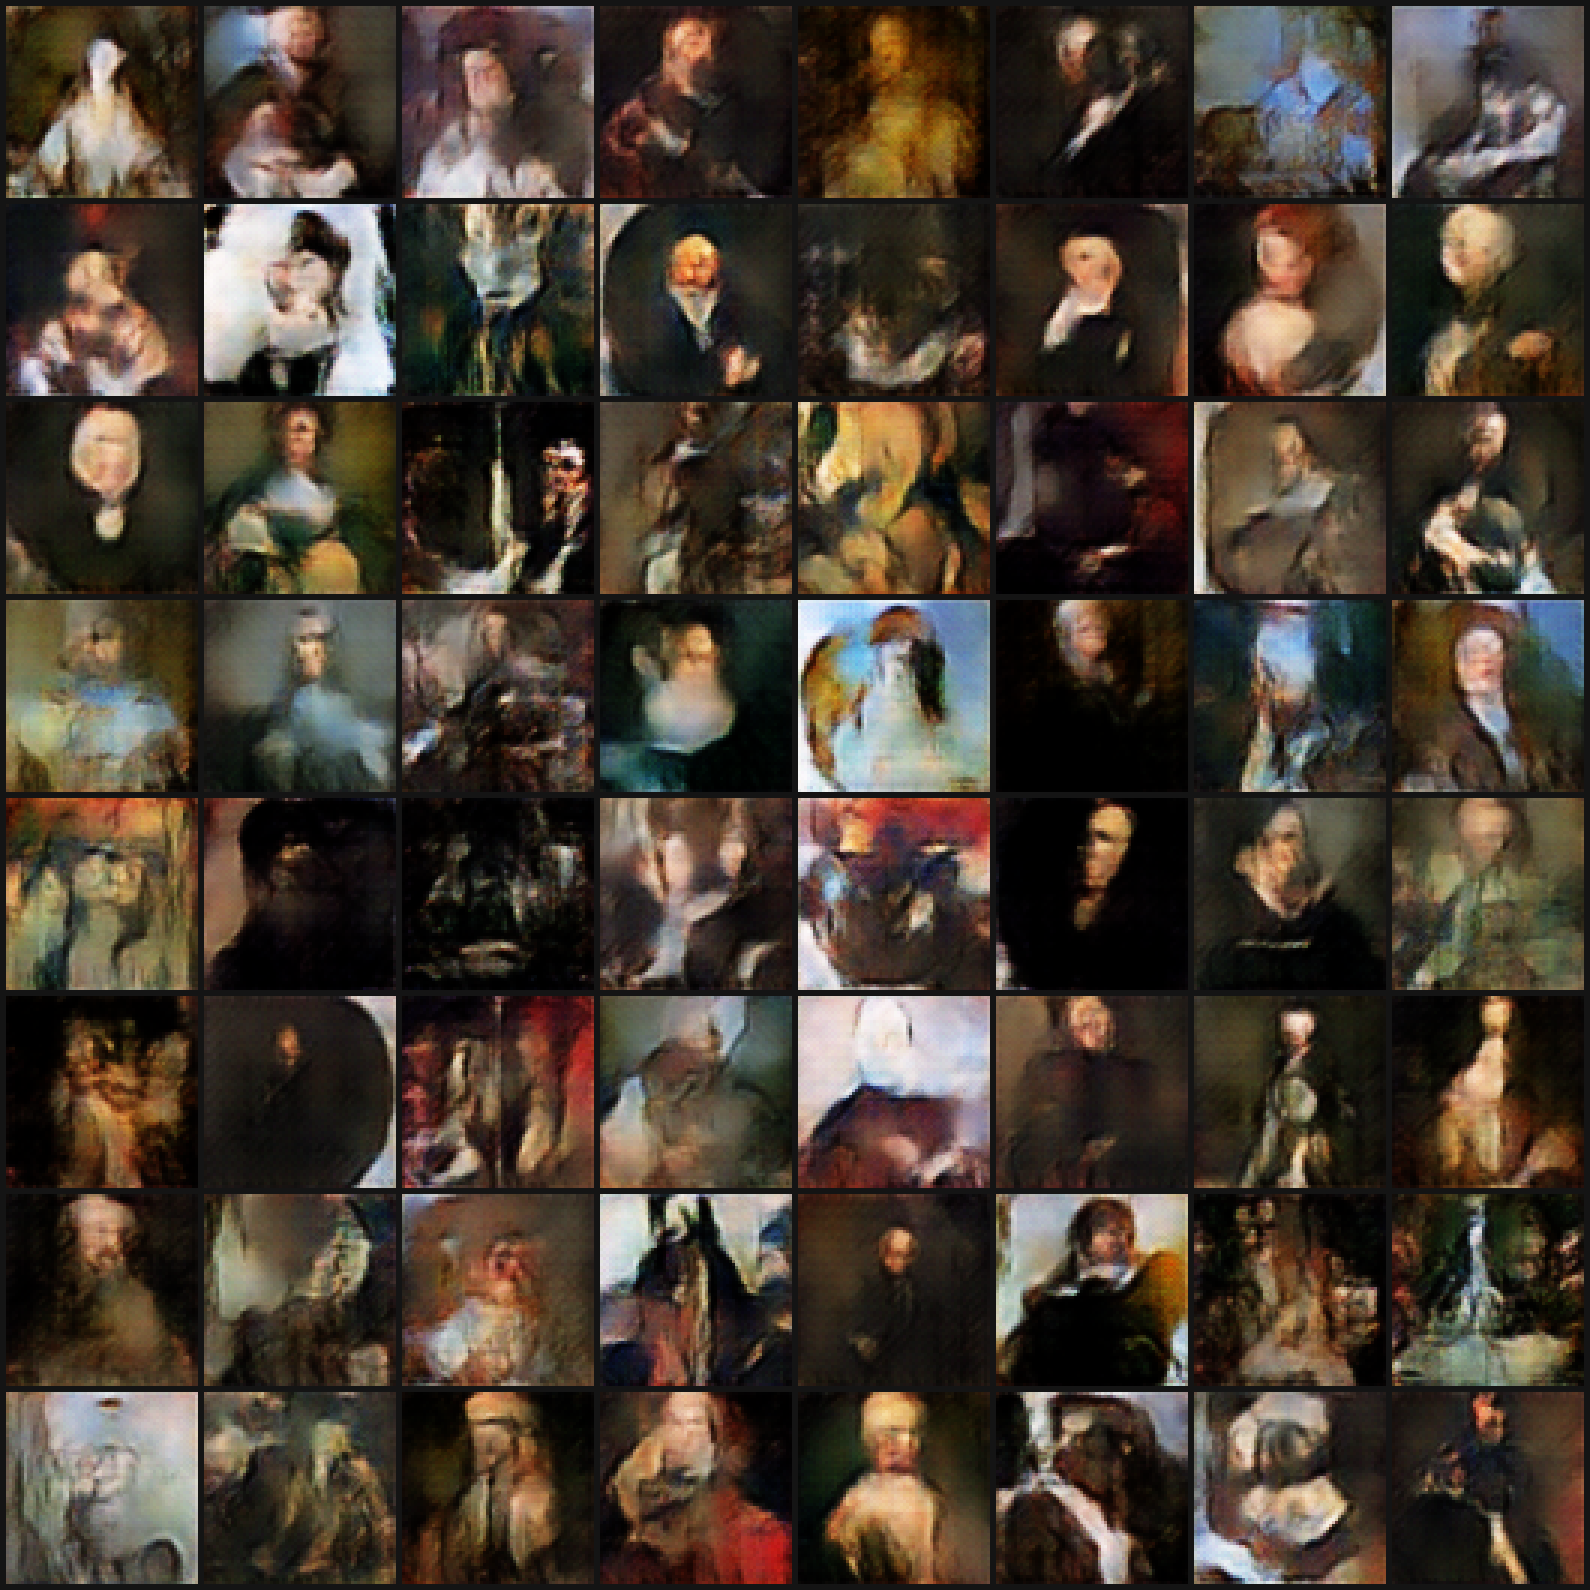

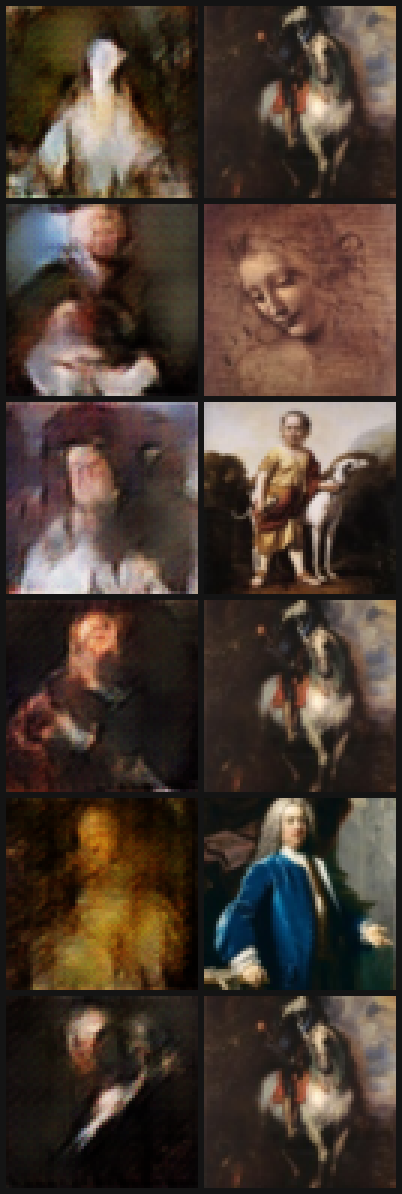

Portraits 128x128 : images generees, puis generee / plus proche reelle


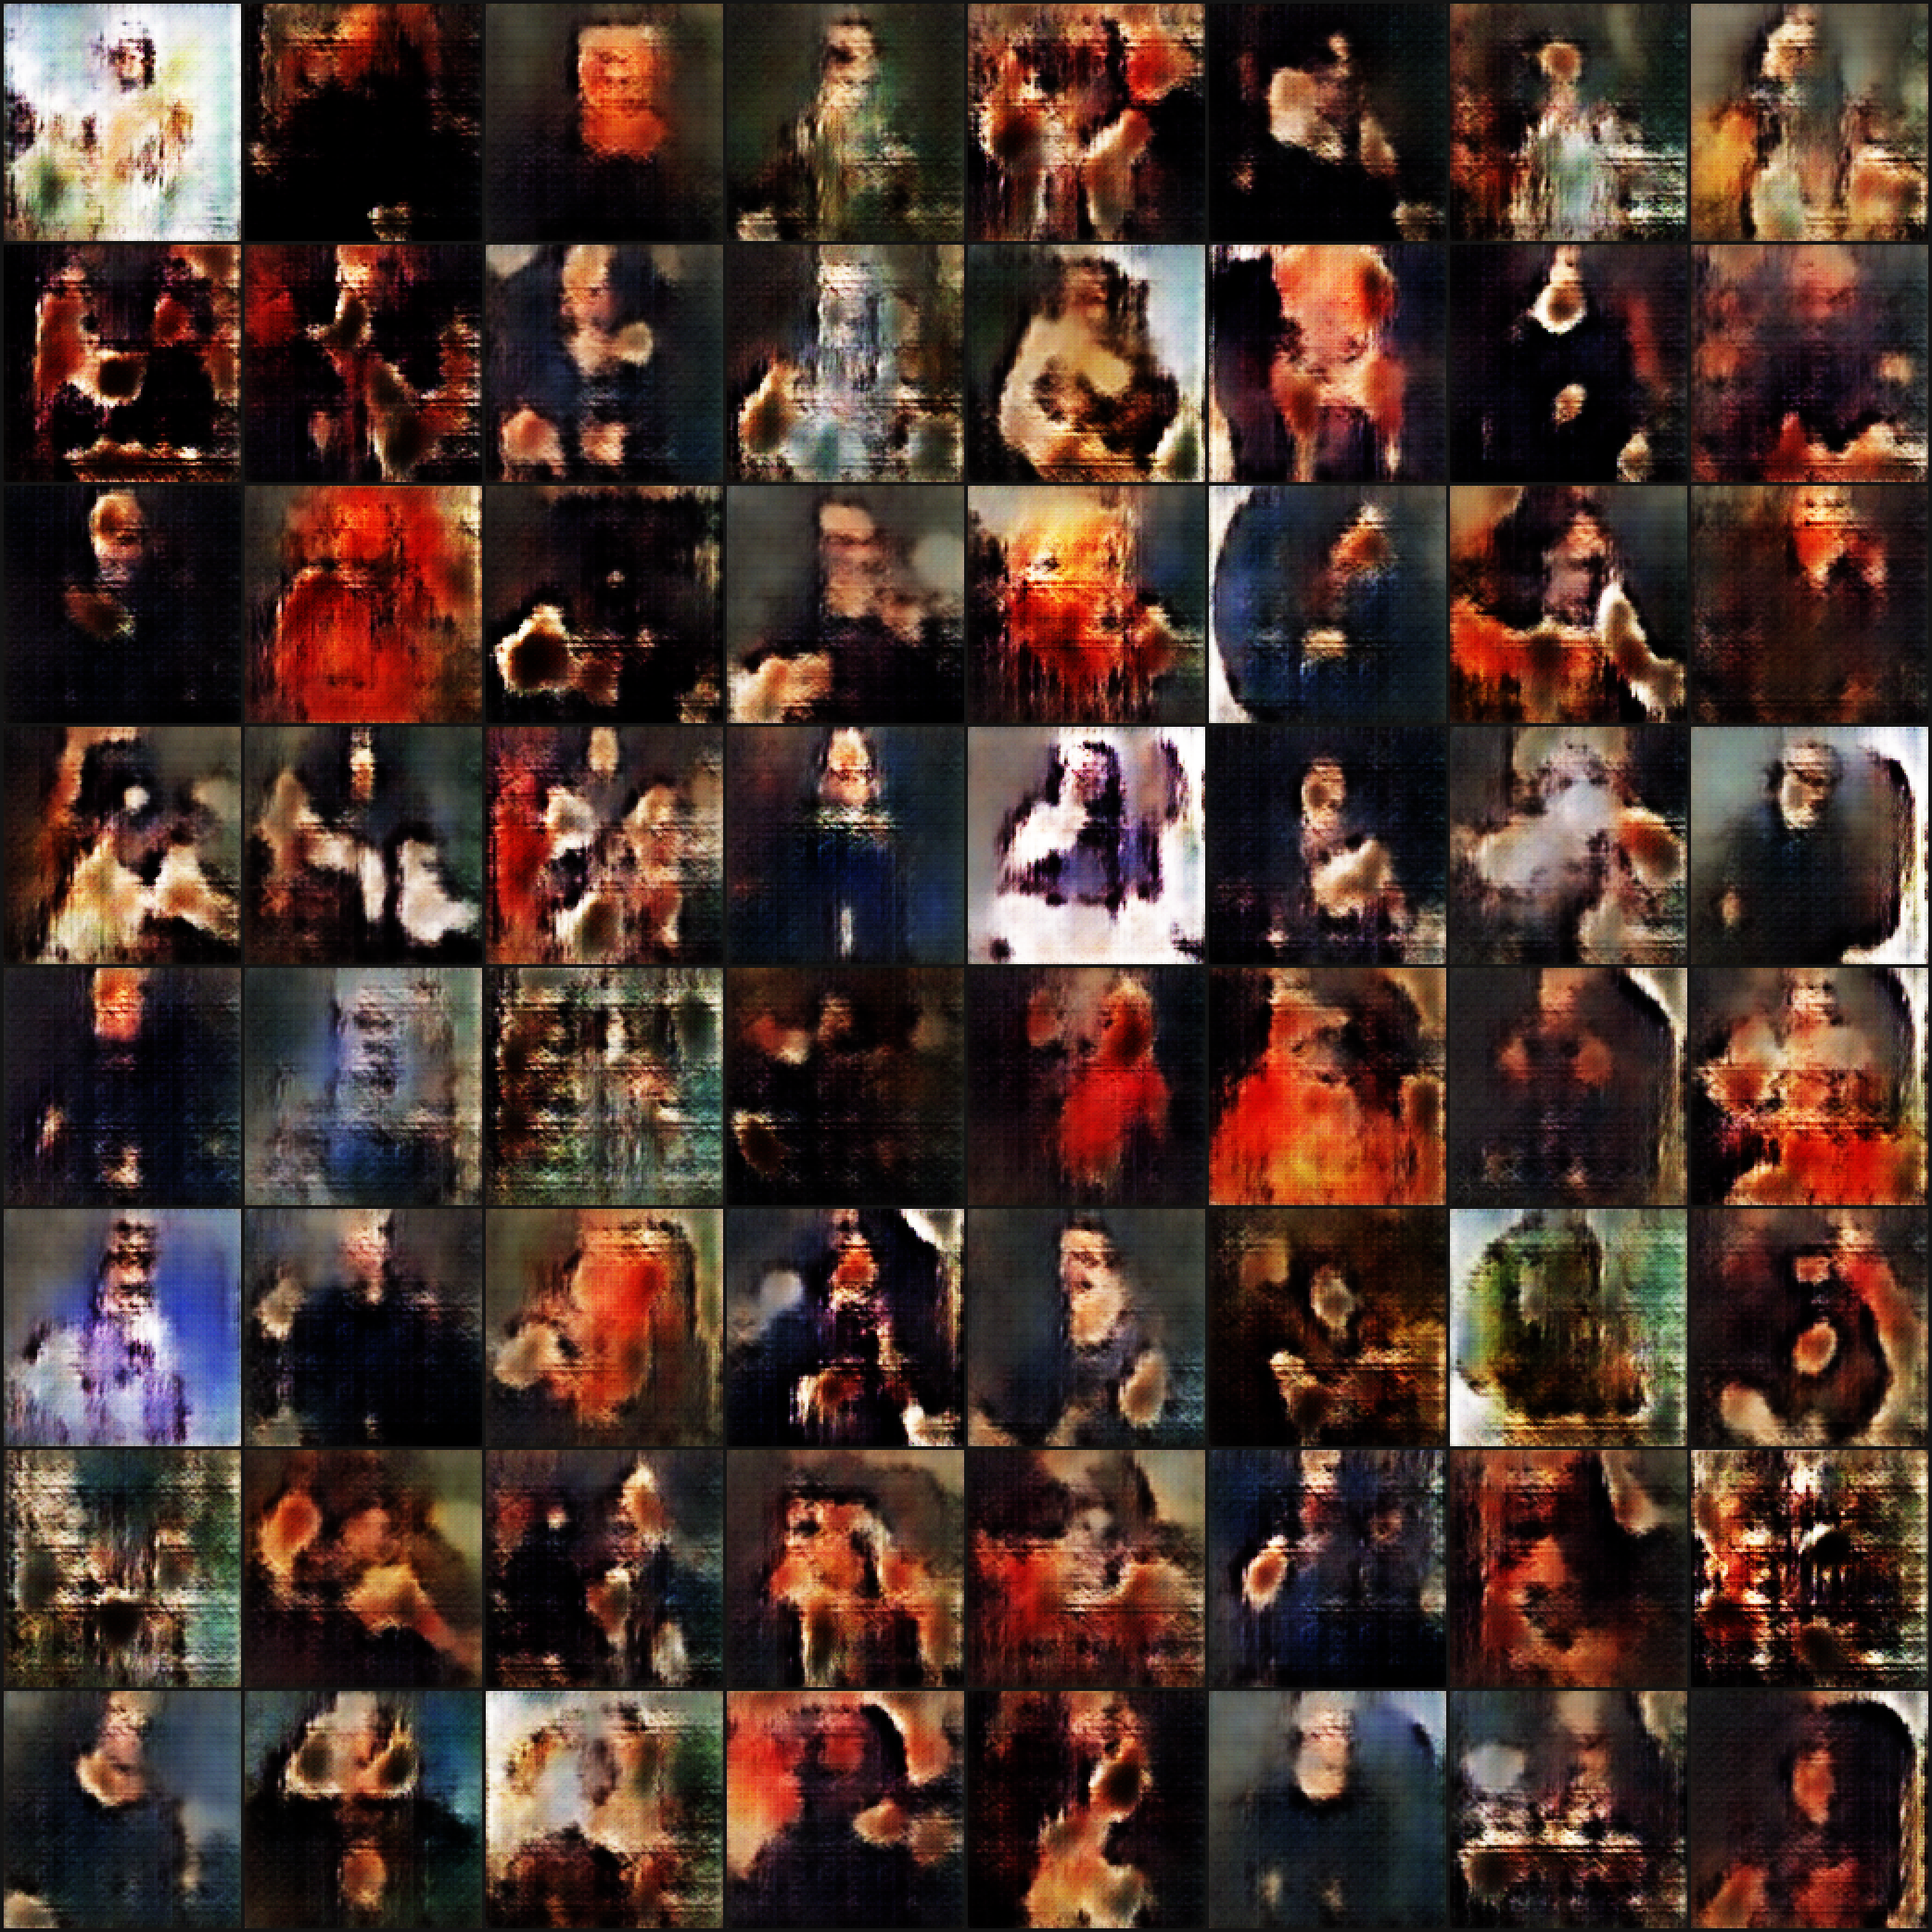

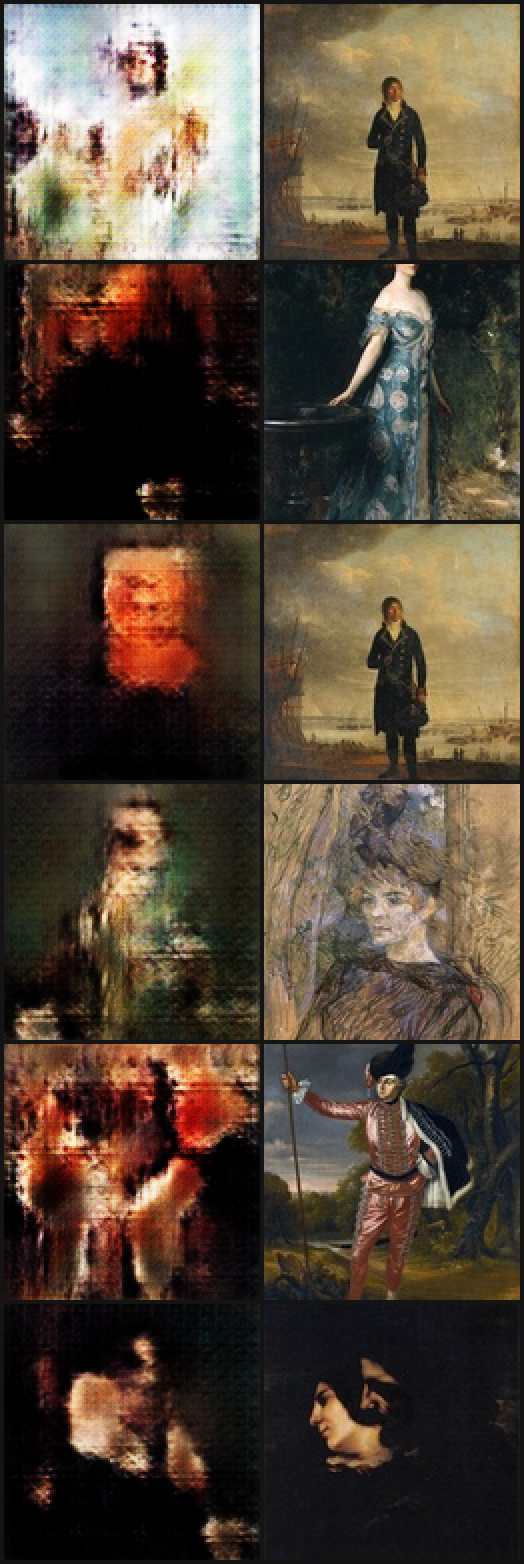

In [6]:
for size in (64, 128):
    print(f"Portraits {size}x{size} : images generees, puis generee / plus proche reelle")
    display(Show(filename=str(ROOT / "reports" / f"portraits_{size}" / "figures" / "samples.png"), width=640))
    display(Show(filename=str(ROOT / "reports" / f"portraits_{size}" / "figures" / "nearest_neighbors.png"), width=240))

## 6. Conclusions

**La règle 4 du cours se vérifie sur nos données.** À architecture, hyperparamètres et nombre
d'itérations identiques, le jeu homogène donne des images nettement plus lisibles : presque chaque image
est un portrait (silhouette centrée, visage clair, buste, fond sombre, perruques ou cols blancs), là où le
modèle tous genres restait abstrait. L'écart à la référence passe de ×3,4 à ×2,8.

**Le 128×128 n'a pas fait mieux, dans nos conditions.** Avec deux fois moins d'itérations pour un modèle
3,5 fois plus gros, il reste derrière le 64×64 (×3,8) : traînées horizontales, couleurs saturées,
silhouettes moins lisibles. Ce n'est pas une preuve que le 128×128 est moins bon, mais que la règle 1 du
cours a un coût : il faut bien plus d'entraînement, idéalement sur GPU.

**Pas de recopie** : pour les deux modèles, les plus proches voisins dans le jeu d'entraînement sont des
tableaux différents.

**Modèle retenu pour l'application : portraits 64×64.**

Pistes : entraîner le 128×128 plus longtemps sur GPU (Colab), adoucir les étiquettes du discriminateur,
remplacer les convolutions transposées par un agrandissement suivi d'une convolution (traînées et
damiers), DiffAugment pour mieux exploiter un petit jeu de 3 347 images.